In [ ]:
import pandas as pd
import numpy as np
import glob
from sklearn.decomposition import NMF
from scipy.optimize import linear_sum_assignment
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from matplotlib import pyplot as plt
import seaborn as sns

In [3]:
df_str = pd.read_csv("../data/filtered_df.csv", index_col=0)
k_imp = SimpleImputer(missing_values = np.nan, strategy = "mean")
scaler = StandardScaler()
df_imputed = k_imp.fit_transform(df_str.T)
df_scaled = scaler.fit_transform(df_imputed)

X_data = df_scaled
X_pos = np.clip(X_data, a_min=0, a_max=None)        # keep only values above mean
X_neg = np.clip(-X_data, a_min=0, a_max=None)

In [4]:
K = 13
model_pos = NMF(n_components = K, 
            init = 'nndsvd', 
            solver = "cd",
            max_iter = 100000)
Q_pos = model_pos.fit_transform(X_pos)

model_neg = NMF(n_components = K, 
            init = 'nndsvd', 
            solver = "cd",
            max_iter = 100000)
Q_neg = model_neg.fit_transform(X_neg)
Q_pos /= Q_pos.sum(axis=1, keepdims=True)
Q_neg /= Q_neg.sum(axis=1, keepdims=True)

<Axes: >

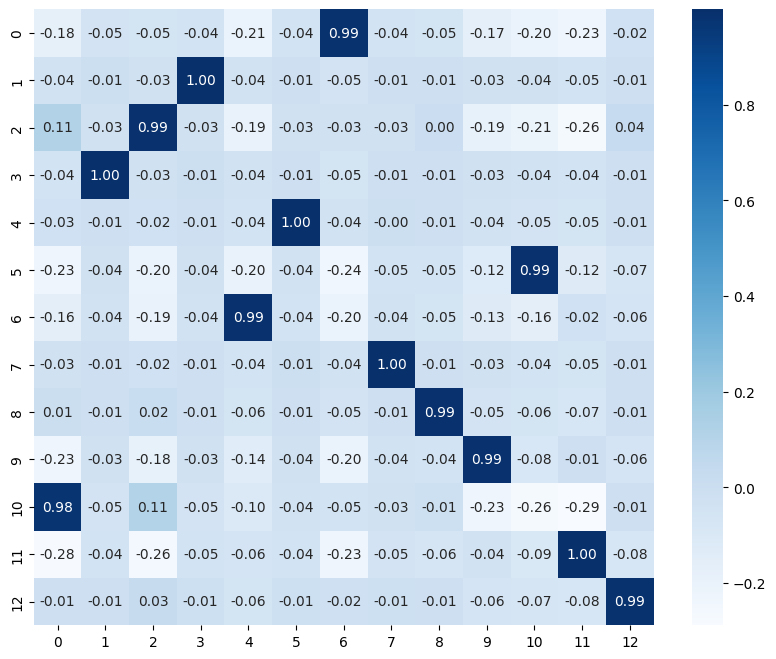

In [5]:
corr_matrix = np.corrcoef(Q_pos.T, Q_neg.T)[:K, K:] 
fig, g = plt.subplots(1, 1, figsize = (10,8), dpi = 100)
sns.heatmap(corr_matrix,annot=True, fmt='.2f', cmap = "Blues")

In [6]:
cost_matrix = -np.abs(corr_matrix)
row_ind, col_ind = linear_sum_assignment(cost_matrix)
total_corr = corr_matrix[row_ind, col_ind]
total_corr.mean()

0.99222427025553

In [8]:
nmf_pos = pd.DataFrame(Q_pos)
nmf_neg = pd.DataFrame(Q_neg)
nmf_pos["sample"] = df_str.columns
nmf_neg["sample"] = df_str.columns
nmf_pos.to_csv("../results/dnmf_pos13.csv", index=False)
nmf_neg.to_csv("../results/dnmf_neg13.csv", index=False)

In [ ]:
res_list = glob.glob("./choose_k/*.csv")
cvn = pd.read_csv(res_list[0])
for i in range(1, len(res_list)):
    cvi = pd.read_csv(res_list[i])
    cvn = pd.concat([cvn, cvi], axis = 0)
df_cv1 = pd.melt(cvn, id_vars=["K"], value_vars=["avercorr", "varcorr", "match"])
#df_cv1.to_csv("./figure3/kg_cv/kg_cv_3_25.csv", index=False)
df_cv1 = df_cv1.query("K>2").query("K<16")

In [ ]:
fig, g = plt.subplots(1, 1, figsize = (8,4), dpi = 100, 
                       sharey = True)
sns.set_context("talk", font_scale = 0.9)
sns.set_style("white")
sns.boxplot(ax = g,
            x = 'K', y = 'value', 
            data = df_cv1.query("variable == 'avercorr' "),
            fliersize = 5)
#g.set_title("HGDP + SGDP")
#g.set_ylabel("Shared components")
g.set_ylabel("Average correlation")
g.set_xlabel("Number of components (K)")